# FarmRL: reinforcement learning for crop input management

**Team:** Harshita Vachhani (B23EE1026), Aurindum Banerjee (B23CS1006) · AI Assignment 2

This notebook is the end-to-end record of the project: data, yield model, environment,
training and evaluation. All logic lives in `src/farmrl/`; the notebook only calls it and
plots. Every figure is also saved to `results/figures/` at 300 dpi for the report.

## 1. Introduction and RL formulation

A wheat farmer in Punjab decides, fortnight by fortnight, how much nitrogen to apply,
whether to irrigate and whether to spray, without knowing the rest of the season's weather.
Too little input loses yield; too much wastes money, leaches nitrate, draws down groundwater
and (for water) directly hurts the crop. We model one season as an episodic Markov decision
process and train an agent to maximise net profit per hectare.

**Episode.** One wheat season at Ludhiana, sown on 1 November, in $T = 12$ fortnightly steps.
Each episode replays the weather of one real season.

**State** (11 numbers, all observed by the agent):

$$
s_t = \big(\,t/T,\; \theta_t,\; N^{soil}_t,\; p_t,\; \textstyle\sum_{k<t} R_k,\; \sum_{k<t} n_k,\; \sum_{k<t}(R_k + w_k),\; P/P_0,\; R_{t-1},\; ET_{0,t-1},\; \rho_t \big)
$$

with $\theta$ soil moisture (fraction of capacity), $N^{soil}$ soil mineral nitrogen, $p$ pest
pressure, $R$ rainfall, $P$ the season's wheat price, and
$\rho_t = \sum ET_a / \sum ET_c$ the share of crop water demand met so far.

**Action.** $a_t = (n_t, w_t, q_t)$, a `MultiDiscrete([3, 3, 3])` choice of

$$
n_t \in \{0, 20, 40\}\ \text{kg N/ha}, \qquad w_t \in \{0, 37.5, 75\}\ \text{mm}, \qquad q_t \in \{0, 1, 2\}\ \text{(pesticide dose)}.
$$

**Transition.** A soil water bucket driven by real rain and reference evapotranspiration,
a soil nitrogen pool, and a stochastic pest population:

$$
\theta_{t+1} = \frac{\min\{C,\; \theta_t C + R_t + w_t - D_t\} - ET_{a,t}}{C}, \qquad
N^{soil}_{t+1} = \gamma_N (1 - \ell_t) N^{soil}_t + n_t, \qquad
p_{t+1} = \mathrm{clip}\big(p_t\, g_t\, (1 - \kappa q_t),\, 0,\, 1\big)
$$

where $D_t$ is drainage, $\ell_t$ the leached share and $g_t = 1 + U(0.1, 0.6)\cdot RH_t/\overline{RH}$.

**Reward.** Input costs and environmental penalties are paid every step, the crop is sold at harvest:

$$
r_t = -\frac{1}{\kappa_r}\Big[\underbrace{c_N n_t + c_W w_t + c_P q_t}_{\text{input cost}}
 + \underbrace{\lambda_N \max(0, N^{soil}_{t+1} - 80) + \lambda_P q_t + \lambda_W w_t}_{\text{environmental penalty}}\Big]
 + \frac{\mathbb{1}[t = T-1]}{\kappa_r}\,\big(Y \cdot P - F\big)
$$

$$
Y = y_{max}\,\big[1 - e^{-\beta_N (N_{eff} + N_0)}\big]\,\Big[1 - \beta_W \max\big(0, \tfrac{W - W^*}{100}\big)^2\Big]\,\big[1 - K_y (1 - \rho_T)\big]\,\big[1 - L\, D_{pest}\big]
$$

$F$ is the fixed cost of the season (labour, machinery, seed, ...), $\kappa_r = 10^4$ only rescales
the reward. The objective is $\max_\pi \mathbb{E}\big[\sum_{t=0}^{T-1} \gamma^t r_t\big]$ with $\gamma = 0.99$.
We report **net profit** $Y P - F - \sum_t(\text{input cost})$ in INR/ha, i.e. the reward without
the penalty terms.

**Algorithm.** Proximal Policy Optimisation with a clipped surrogate objective and GAE,
implemented from scratch in `src/farmrl/agents/ppo.py`.

In [1]:
import sys, json, warnings
from pathlib import Path

ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from farmrl import data_loader as dl
from farmrl.yield_model import YieldModel, PRIORS
from farmrl.env import FarmEnv, OBS_NAMES
from farmrl.baselines import BASELINES, recommended_schedule
from farmrl.evaluation import evaluate, summarise, run_episode
from farmrl.agents.ppo import PPO
from farmrl.utils import load_config, set_seed, save_fig, set_plot_style, COLORS, POLICY_COLORS

cfg = load_config(ROOT / "configs/default.yaml")
SEED = cfg["env"]["seed"]
set_seed(SEED)
set_plot_style()
pd.set_option("display.precision", 2)
MUTED = "#898781"

def show(fig, name):
    path = save_fig(fig, name)
    plt.show()
    print("saved", path.relative_to(ROOT))

## 2. Data loading and exploratory analysis

`scripts/download_data.py` fetches the raw files and `farmrl.data_loader` cleans them into
`data/processed/`. Nothing below is synthetic: a dataset that could not be obtained is
reported as missing and the corresponding plot is skipped.

| Dataset | Used for | Status |
|---|---|---|
| NASA POWER daily weather, Ludhiana, 1985–2024 | environment weather | downloaded |
| NASA POWER daily weather at 220 district centroids, 2007–2018 | season rain, temperature, heat-stress days for the yield fit | downloaded (cached) |
| ICRISAT district-level data: crops, fertiliser, irrigated area, harvest prices | wheat panel for the yield fit; region harvest prices | supplied manually: all India, 2008–2017 |
| RBI Handbook, wheat MSP by crop year | price series where there is no harvest price | downloaded |
| CACP Rabi price policy report 2027-28 | per-hectare costs (Punjab, 2024-25) | downloaded, table transcribed |
| FAO yield + pesticides (Kaggle `yield_df.csv` + source files) | calibrating the pesticide loss | supplied manually: India wheat, 1990–2013 |
| Agmarknet mandi prices | market price series | needs data.gov.in key / manual export |

The cell below reports what is actually on disk.

In [2]:
REGION = cfg["env"]["region"]
daily = dl.load_weather(cfg["env"]["weather_site"])
seasons = dl.load_seasons(cfg["env"]["weather_site"], steps=cfg["env"]["steps_per_season"])
summary = dl.season_summary(seasons)
train_years, test_years = dl.split_seasons(seasons, cfg["env"]["train_end"])
icrisat = dl.load_icrisat("wheat", min_area_kha=cfg["yield_fit"]["min_area_kha"])
fit_table = dl.build_fit_table("wheat", min_area_kha=cfg["yield_fit"]["min_area_kha"])
prices = dl.load_prices(region=REGION)
costs = dl.load_cost_of_cultivation(state=REGION.title())

def optional(loader):
    try:
        return loader()
    except FileNotFoundError as err:
        print("MISSING:", err)

fao = optional(dl.load_fao_pesticides)
mandi = optional(dl.load_agmarknet)

print(f"weather   : {len(daily)} days, {daily['date'].min():%Y-%m-%d} to {daily['date'].max():%Y-%m-%d}; "
      f"{summary['season'].nunique()} complete seasons")
print(f"ICRISAT   : {len(icrisat)} district-years with > {cfg['yield_fit']['min_area_kha']:.0f} thousand ha of wheat, "
      f"{icrisat['state'].nunique()} states, {icrisat['district'].nunique()} districts, {icrisat['year'].min()}-{icrisat['year'].max()}")
print(f"fit table : {len(fit_table)} district-years with weather; "
      f"{fit_table.dropna(subset=['n_kg_ha', 'irrigated_share']).shape[0]} with nitrogen and irrigated share")
print(f"prices    : {len(prices)} seasons {prices['season'].min()}-{prices['season'].max()}, "
      f"sources {sorted(prices['source'].unique())}")
print(f"costs     : CACP years {sorted(costs['year'].unique())}")
print(f"FAO       : {'%d years' % len(fao) if fao is not None else 'not available'}")
print(f"Agmarknet : {'%d months' % len(mandi) if mandi is not None else 'not available'}")

MISSING: D:\MyStuff\College\.7thSemester\AI\Ass2\FarmRL\data\raw\agmarknet_wheat_punjab.csv not found -- see scripts/download_data.py prices
weather   : 14610 days, 1985-01-01 to 2024-12-31; 39 complete seasons
ICRISAT   : 2071 district-years with > 10 thousand ha of wheat, 15 states, 220 districts, 2008-2017
fit table : 2071 district-years with weather; 1724 with nitrogen and irrigated share
prices    : 45 seasons 1981-2025, sources ['ICRISAT farm harvest price (Punjab districts)', 'MSP (RBI Handbook)']
costs     : CACP years ['2022-23', '2023-24', '2024-25']
FAO       : 24 years
Agmarknet : not available


### 2.1 Rainfall

Wheat is a winter (rabi) crop: the season is dry, with on average about 110 mm of rain
between November and April, most of it from western disturbances in January–March. The
spread between years is large, which is what makes a fixed irrigation calendar wasteful.

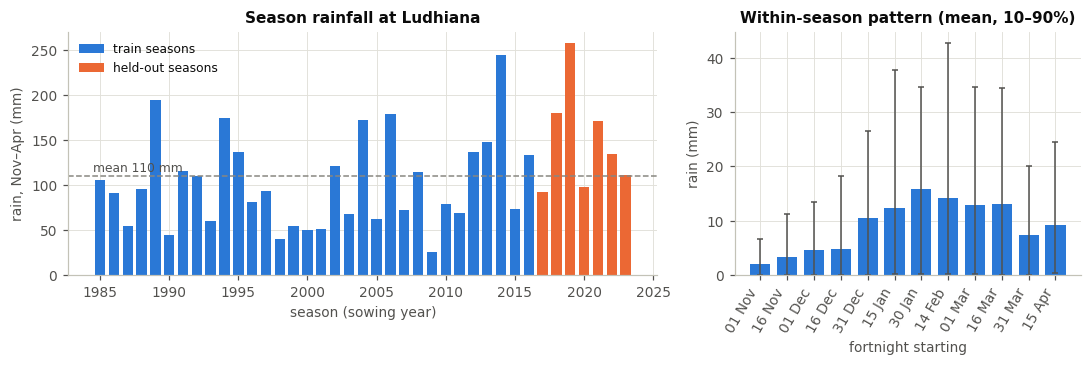

saved results\figures\eda_rainfall.png


In [3]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4), gridspec_kw={"width_ratios": [1.7, 1]})
ax = axes[0]
is_test = summary["season"] > cfg["env"]["train_end"]
ax.bar(summary["season"][~is_test], summary["rain_mm"][~is_test], color=COLORS[0], width=0.75, label="train seasons")
ax.bar(summary["season"][is_test], summary["rain_mm"][is_test], color=COLORS[1], width=0.75, label="held-out seasons")
ax.axhline(summary["rain_mm"].mean(), color=MUTED, lw=1, ls="--")
ax.text(summary["season"].min() - 0.5, summary["rain_mm"].mean() + 5, f"mean {summary['rain_mm'].mean():.0f} mm", color="#52514e", fontsize=8)
ax.set(xlabel="season (sowing year)", ylabel="rain, Nov–Apr (mm)", title="Season rainfall at Ludhiana")
ax.legend(loc="upper left")

ax = axes[1]
by_step = seasons.groupby("step")["rain_mm"]
labels = seasons[seasons["season"] == seasons["season"].min()]["start_date"].map(lambda d: pd.Timestamp(d).strftime("%d %b"))
ax.bar(range(len(labels)), by_step.mean(), color=COLORS[0], width=0.75)
ax.errorbar(range(len(labels)), by_step.mean(), yerr=[by_step.mean() - by_step.quantile(0.1), by_step.quantile(0.9) - by_step.mean()],
            fmt="none", ecolor="#52514e", elinewidth=1, capsize=2)
ax.set_xticks(range(len(labels))); ax.set_xticklabels(labels, rotation=60, ha="right")
ax.set(xlabel="fortnight starting", ylabel="rain (mm)", title="Within-season pattern (mean, 10–90%)")
fig.tight_layout()
show(fig, "eda_rainfall")

### 2.2 Temperature and evaporative demand

Temperature falls to a minimum in January and climbs steeply from March; the last fortnights
are hot and dry, so crop water demand ($ET_c = K_c \cdot ET_0$) peaks during grain filling.
Reference evapotranspiration $ET_0$ is computed from temperature and solar radiation
(Hargreaves radiation form) in `data_loader.load_weather`.

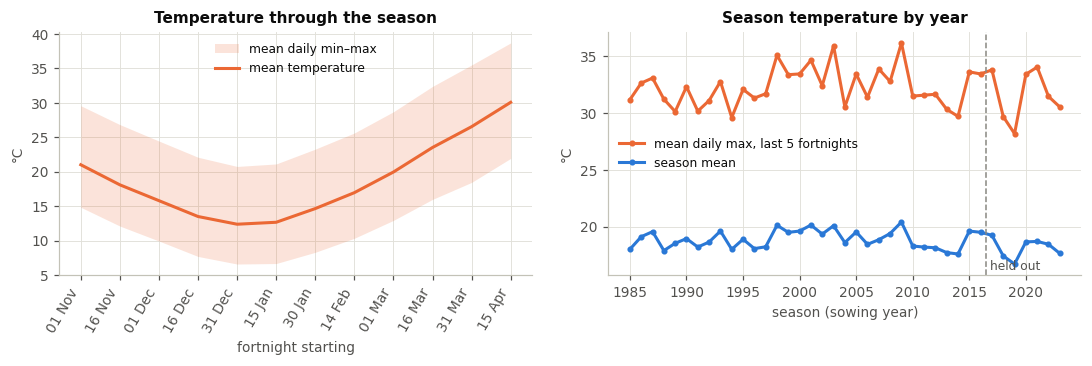

saved results\figures\eda_temperature.png


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
ax = axes[0]
g = seasons.groupby("step")
fx = range(len(labels))
ax.fill_between(fx, g["t_min"].mean(), g["t_max"].mean(), color=COLORS[1], alpha=0.18, lw=0, label="mean daily min–max")
ax.plot(fx, g["t_mean"].mean(), color=COLORS[1], label="mean temperature")
ax.set_xticks(fx); ax.set_xticklabels(labels, rotation=60, ha="right")
ax.set(xlabel="fortnight starting", ylabel="°C", title="Temperature through the season")
ax.legend(loc="upper center")

ax = axes[1]
ax.plot(summary["season"], summary["late_t_max"], color=COLORS[1], marker="o", ms=3, label="mean daily max, last 5 fortnights")
ax.plot(summary["season"], summary["t_mean"], color=COLORS[0], marker="o", ms=3, label="season mean")
ax.axvline(cfg["env"]["train_end"] + 0.5, color=MUTED, lw=1, ls="--")
ax.text(cfg["env"]["train_end"] + 0.8, ax.get_ylim()[0] + 0.5, "held out", color="#52514e", fontsize=8)
ax.set(xlabel="season (sowing year)", ylabel="°C", title="Season temperature by year")
ax.legend(loc="center left")
fig.tight_layout()
show(fig, "eda_temperature")

### 2.3 Yield trends

The ICRISAT panel now covers every state with meaningful wheat area: district-years with
more than 10,000 ha of wheat, 2008–2017. The states differ far more from each other than
years do within a state: Punjab and Haryana sit near 45 q/ha, the central and southern
states at 10–25 q/ha. That between-state gap is what a pooled model has to explain with
irrigation, nitrogen and climate, and what the state fixed effects absorb when it cannot.

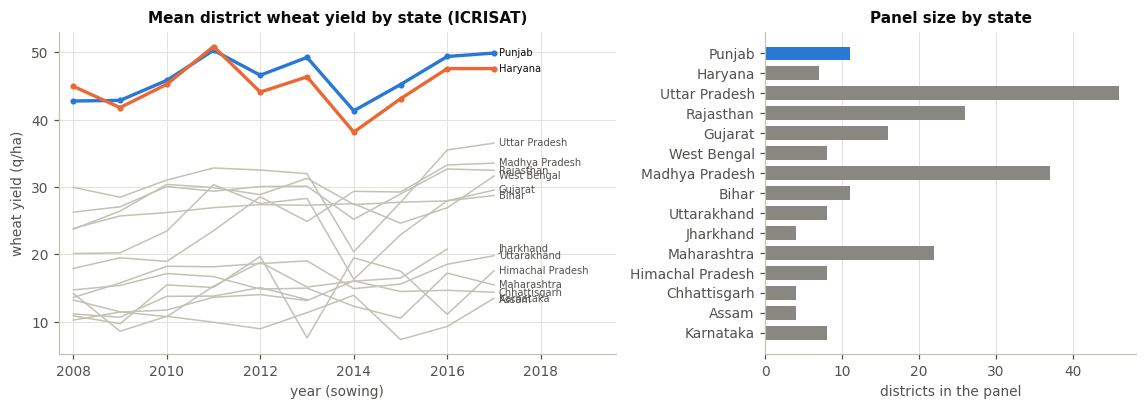

saved results\figures\eda_yield_trends.png


In [5]:
state_year = icrisat.groupby(["state", "year"])["yield_q_ha"].mean().unstack("state")
order = state_year.mean().sort_values(ascending=False).index
fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.8), gridspec_kw={"width_ratios": [1.5, 1]})
ax = axes[0]
for s in order:
    focus = s.lower() in (REGION.lower(), "haryana")
    ax.plot(state_year.index, state_year[s], color=COLORS[0] if s.lower() == REGION.lower() else COLORS[1] if focus else "#c3c2b7",
            lw=2.2 if focus else 1, marker="o" if focus else None, ms=3, zorder=3 if focus else 2)
    ax.text(state_year.index[-1] + 0.1, state_year[s].dropna().iloc[-1], s, fontsize=6.5, va="center",
            color="#0b0b0b" if focus else "#52514e")
ax.set(xlabel="year (sowing)", ylabel="wheat yield (q/ha)", title="Mean district wheat yield by state (ICRISAT)")
ax.set_xlim(state_year.index.min() - 0.3, state_year.index.max() + 2.6)
ax = axes[1]
counts = icrisat.groupby("state")["district"].nunique().loc[order][::-1]
ax.barh(counts.index, counts.values, color=[COLORS[0] if s.lower() == REGION.lower() else "#898781" for s in counts.index], height=0.7)
ax.set(xlabel="districts in the panel", title="Panel size by state")
ax.grid(axis="y", visible=False)
fig.tight_layout()
show(fig, "eda_yield_trends")

### 2.4 What goes with yield: nitrogen, irrigation, rain and heat

Across India the picture is very different from the Haryana-only data used before.
Nitrogen now spans zero to over 400 kg/ha (most districts below 250) and yield clearly
rises with it (r = +0.54). The share of the wheat area that is irrigated separates low- from
high-yield districts just as strongly. Season rain is weakly *negatively* related to yield
in the raw data (r = −0.11), because the rainiest districts are the unirrigated hill and
eastern ones. Heat-stress days (maximum above 30 °C between 15 February and 31 March) are
many in the centre and south, fewer in the north-west and almost absent in the hills; their
raw correlation with yield is weak.

These drivers are strongly correlated with each other across states, so the raw scatter
plots overstate each one; the pooled fit below separates them as far as the data allow.

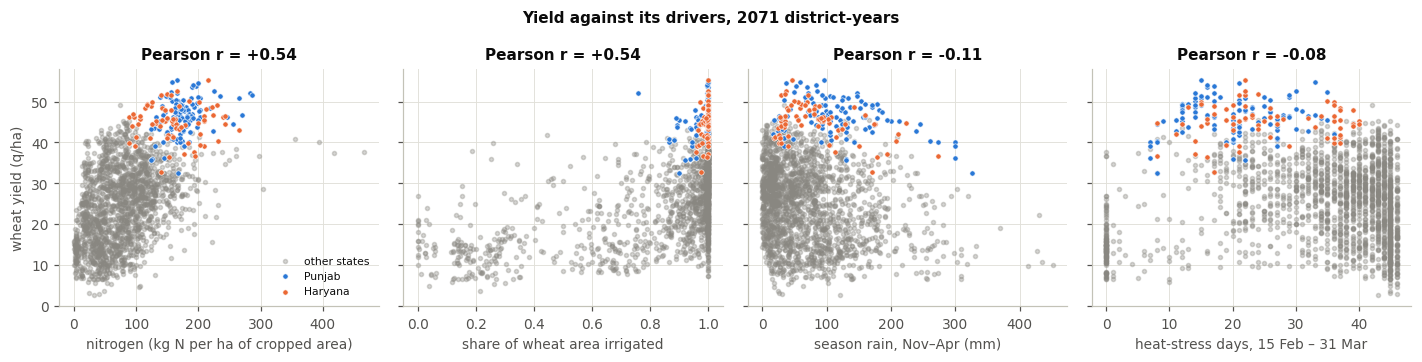

saved results\figures\eda_fertiliser_vs_yield.png


,yield_q_ha,n_kg_ha,irrigated_share,rain_mm,heat_days,harvest_price
state,,,,,,
Punjab,46.3,176.4,1.0,118.5,20.2,1306.9
Haryana,45.0,161.4,1.0,84.1,25.5,1340.3
Uttar Pradesh,30.7,117.7,1.0,70.2,33.3,1253.3
Rajasthan,29.2,43.4,1.0,37.4,34.2,1463.4
Gujarat,28.3,95.9,0.9,20.5,43.1,1538.6
West Bengal,26.6,89.3,NaN,115.7,38.1,1357.6
Madhya Pradesh,25.9,47.8,0.9,64.0,39.1,1428.6
Bihar,24.6,138.0,0.9,51.0,38.3,1214.6
Uttarakhand,17.3,48.1,0.4,138.6,1.6,1498.5


In [6]:
drivers = [("n_kg_ha", "nitrogen (kg N per ha of cropped area)"), ("irrigated_share", "share of wheat area irrigated"),
           ("rain_mm", "season rain, Nov–Apr (mm)"), ("heat_days", "heat-stress days, 15 Feb – 31 Mar")]
focus_states = [REGION.title(), "Haryana"] if REGION.lower() != "haryana" else ["Haryana"]
fig, axes = plt.subplots(1, 4, figsize=(13, 3.3), sharey=True)
for ax, (col, xlabel) in zip(axes, drivers):
    d = fit_table.dropna(subset=[col])
    rest = d[~d["state"].isin(focus_states)]
    ax.scatter(rest[col], rest["yield_q_ha"], s=7, color="#898781", alpha=0.35, label="other states")
    for c, s_name in zip(COLORS, focus_states):
        g = d[d["state"] == s_name]
        ax.scatter(g[col], g["yield_q_ha"], s=12, color=c, edgecolor="white", lw=0.4, label=s_name)
    ax.set(xlabel=xlabel, title=f"Pearson r = {d[[col, 'yield_q_ha']].corr().iloc[0, 1]:+.2f}")
axes[0].set_ylabel("wheat yield (q/ha)")
axes[0].legend(fontsize=7, loc="lower right")
fig.suptitle(f"Yield against its drivers, {len(fit_table)} district-years", fontsize=10, fontweight="bold")
fig.tight_layout()
show(fig, "eda_fertiliser_vs_yield")
display(fit_table.groupby("state")[["yield_q_ha", "n_kg_ha", "irrigated_share", "rain_mm", "heat_days", "harvest_price"]].mean().round(1)
        .sort_values("yield_q_ha", ascending=False))

### 2.5 Pesticide versus yield

The FAO table is a single national series: India's wheat yield and total pesticide use (all
crops, tonnes of active ingredient) for 1990–2013. `load_fao_pesticides` collapses the
repeated rows of `yield_df.csv` (one per temperature station) to one row per year and
restores 2003, which the file drops because its rainfall source has no row for that year.
The files carry no cropland area, so pesticide use is expressed as an index (series mean = 1).

Read naively, the series says pesticides *reduce* yield: use fell by half between 1990 and
2008 while yield rose steadily. That is a trend artefact. With the year trend and
temperature removed (right panel) the relation turns weakly positive. Rainfall cannot be
used as a control: the file gives India the same value (1,083 mm) every year.

24 years (1990-2013); 22 repeated rows per year collapsed; 1 year restored from the source files; measure: index (national tonnage / series mean)


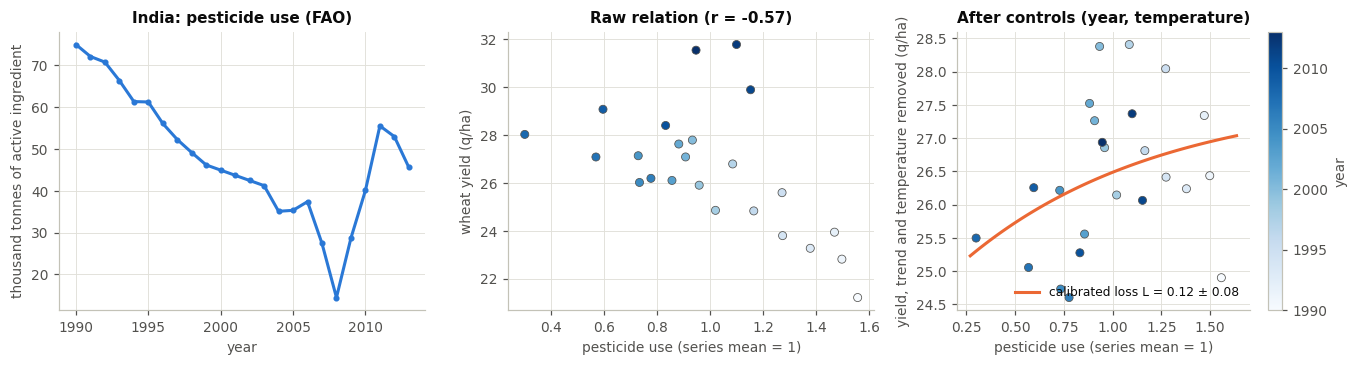

saved results\figures\eda_pesticide_vs_yield.png


In [7]:
if fao is None:
    print("yield_df.csv is not in data/raw, so there is no pesticide data to plot.")
    print("Save it there (or add ~/.kaggle/kaggle.json and run `python scripts/download_data.py kaggle`), then re-run.")
else:
    print(f"{len(fao)} years ({fao['year'].min()}-{fao['year'].max()}); {int(fao['n_temp_rows'].max())} repeated rows per year collapsed; "
          f"{(fao['source'] != 'yield_df.csv').sum()} year restored from the source files; measure: {fao['normalisation'].iloc[0]}")
    cal = YieldModel().calibrate_pesticide(fao)
    fig, axes = plt.subplots(1, 3, figsize=(12.5, 3.4))
    axes[0].plot(fao["year"], fao["pesticides_t"] / 1000, color=COLORS[0], marker="o", ms=3, label="pesticide use (kt)")
    axes[0].set(xlabel="year", ylabel="thousand tonnes of active ingredient", title="India: pesticide use (FAO)")
    sc = axes[1].scatter(cal["x"], cal["observed"], c=cal["year"], cmap="Blues", s=28, edgecolor="#52514e", lw=0.5)
    r = np.corrcoef(cal["x"], cal["observed"])[0, 1]
    axes[1].set(xlabel="pesticide use (series mean = 1)", ylabel="wheat yield (q/ha)", title=f"Raw relation (r = {r:+.2f})")
    axes[2].scatter(cal["x"], cal["partial_yield"], c=cal["year"], cmap="Blues", s=28, edgecolor="#52514e", lw=0.5)
    grid = np.linspace(cal["x"].min() * 0.9, cal["x"].max() * 1.05, 100)
    level = (cal["partial_yield"] / (1 - cal["estimate"] * np.exp(-cal["k_fixed"] * cal["x"]))).mean()
    axes[2].plot(grid, level * (1 - cal["estimate"] * np.exp(-cal["k_fixed"] * grid)), color=COLORS[1],
                 label=f"calibrated loss L = {cal['estimate']:.2f} ± {cal['std_err']:.2f}")
    axes[2].set(xlabel="pesticide use (series mean = 1)", ylabel="yield, trend and temperature removed (q/ha)",
                title=f"After controls ({', '.join(cal['controls'])})")
    axes[2].legend(loc="lower right")
    fig.colorbar(sc, ax=axes[2], label="year")
    fig.tight_layout()
    show(fig, "eda_pesticide_vs_yield")

### 2.6 Prices and costs

The price of a season is the mean ICRISAT **farm harvest price** of the region's districts
where it is reported (seasons 2008–2015), and the wheat minimum support price (MSP)
elsewhere; no mandi series could be downloaded. In Punjab the two are nearly the same,
because most wheat is sold at the MSP. Nominal prices have grown sixteen-fold since 1985,
so old rupee values cannot sit next to today's costs. The environment therefore uses a
**price index**: each year's price relative to the centred five-year trend of its own
source, multiplied by the 2024-25 MSP. The index stays mostly within ±5% of 1, i.e. price
risk is small compared with weather risk.

Costs come from the CACP cost-of-cultivation table for Punjab wheat (2024-25).

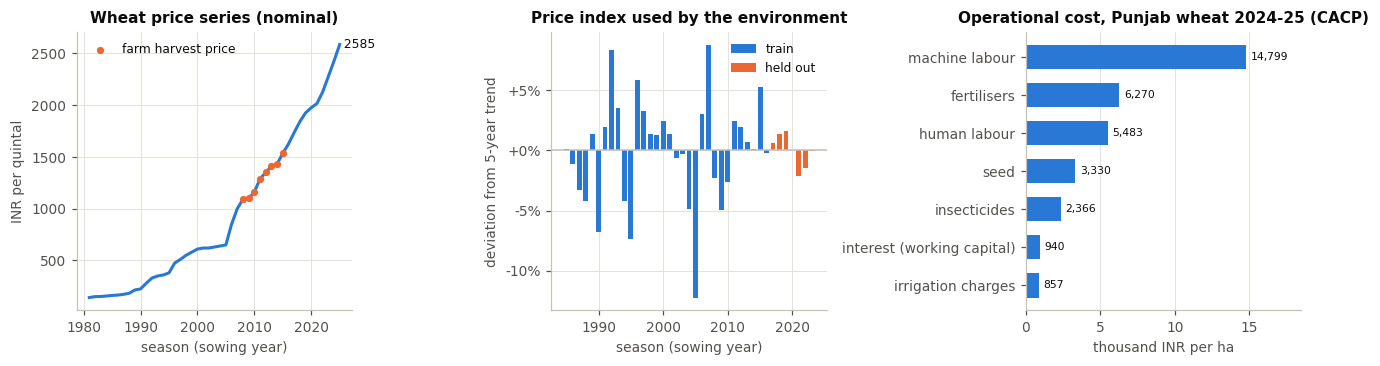

saved results\figures\eda_prices_costs.png
CACP 2024-25: operational cost 34,285 INR/ha, yield 53.0 q/ha


In [8]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.4))
ax = axes[0]
ax.plot(prices["season"], prices["price"], color=COLORS[0])
harvest = prices[prices["source"].str.startswith("ICRISAT")]
ax.scatter(harvest["season"], harvest["price"], s=14, color=COLORS[1], zorder=3, label="farm harvest price")
ax.legend(loc="upper left")
ax.set(xlabel="season (sowing year)", ylabel="INR per quintal", title="Wheat price series (nominal)")
ax.text(prices["season"].iloc[-1], prices["price"].iloc[-1], f" {prices['price'].iloc[-1]:.0f}", va="center", fontsize=8)

ax = axes[1]
p = prices[prices["season"].between(summary["season"].min(), summary["season"].max())]
tr = p["season"] <= cfg["env"]["train_end"]
ax.bar(p["season"][tr], p["price_index"][tr] - 1, color=COLORS[0], width=0.75, label="train")
ax.bar(p["season"][~tr], p["price_index"][~tr] - 1, color=COLORS[1], width=0.75, label="held out")
ax.axhline(0, color="#c3c2b7", lw=1)
ax.set(xlabel="season (sowing year)", ylabel="deviation from 5-year trend", title="Price index used by the environment")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:+.0%}"))
ax.legend()

ax = axes[2]
latest = dl.latest_costs(costs)
year = costs["year"].max()
items = {"machine labour": latest["machine_labour_hired"] + latest["machine_labour_owned"],
         "fertilisers": latest["fertilisers"],
         "human labour": latest["human_labour_casual"] + latest["human_labour_attached"] + latest["human_labour_family"],
         "seed": latest["seed"], "insecticides": latest["insecticides"],
         "interest (working capital)": latest["interest_on_working_capital"],
         "irrigation charges": latest["irrigation_charges"]}
names = list(items)[::-1]
bars = ax.barh(names, [items[k] / 1000 for k in names], color=COLORS[0], height=0.65)
ax.bar_label(bars, labels=[f"{items[k]:,.0f}" for k in names], padding=3, fontsize=7)
ax.set(xlabel="thousand INR per ha", title=f"Operational cost, {REGION.title()} wheat {year} (CACP)")
ax.set_xlim(0, max(items.values()) / 1000 * 1.25); ax.grid(axis="y", visible=False)
fig.tight_layout()
show(fig, "eda_prices_costs")
print(f"CACP {year}: operational cost {latest['operational_cost']:,.0f} INR/ha, yield {latest['yield_q_per_ha']} q/ha")

## 3. Fitting the yield response model

`YieldModel.fit_panel` fits, with `scipy.optimize.curve_fit` (bounded least squares), one
response for all states:

$$
Y = A_{state}\,\big[1 - e^{-\beta_N (N + N_0)}\big]\,\big[1 - k_{dry}\,(1 - \iota)\,e^{-R/R_0}\big]\,
\Big[1 - \beta_W\,\iota\,\max\big(0, \tfrac{R - R^*}{100}\big)^2\Big]\,\big[1 - \beta_H H\big]
$$

with $N$ nitrogen (kg/ha), $\iota$ the irrigated share of the crop, $R$ season rain (mm) and
$H$ heat-stress days. $A_{state}$ is a **state fixed effect**: each state's plateau yield,
standing in for soils, varieties and management that the panel does not record. The terms
are a Mitscherlich response to nitrogen, a loss for the unirrigated share that rain can
offset, a quadratic loss for rain on top of irrigation, and a linear loss per hot day.

Rules the fit follows:

* **Held-out years.** The model is first fitted on 2008–2014 and scored on 2015–2017, then
  refitted on all years for use.
* **Identification.** A parameter that ends on a bound or has a standard error larger than
  its estimate is set to its neutral value (no effect) and the rest are refitted.
* **Pesticide loss is calibrated, not fitted.** The district panel has no pesticide data, so
  `pest_loss` comes from the national FAO series of section 2.5:
  $\log Y_t = c + g\,t + b_T T_t + \log\big(1 - L\,e^{-k x_t}\big)$ with the decay $k = 1$ fixed
  (average use leaves 37% of the loss). With 24 national points, total pesticide use across
  all crops and one trending series, this pins down an order of magnitude at best; the
  output states the standard error and how far the estimate is from zero.

All of this, including the comparison with the earlier single-region fit, is
`farmrl.fitting.fit_yield_model`, the same function `scripts/prepare_data.py` runs.

In [9]:
from farmrl import fitting
model, rep = fitting.fit_yield_model(cfg, fit_table, pest_df=fao)
print("\n".join(fitting.describe(model, rep)))

h = rep["holdout"]
scores = pd.DataFrame({"R²": [rep["r2"], h["r2_train"], h["r2_test"], h["r2_test_state_means_only"]],
                       "rows": [rep["n_obs"], h["n_train"], h["n_test"], h["n_test"]]},
                      index=["pooled fit, all years (in-sample)", f"pooled fit, years < {h['from_year']} (in-sample)",
                             f"pooled fit, held-out years >= {h['from_year']}", "state means only, held-out years"])
display(scores.round(3))
if rep["comparison"]:
    display(pd.DataFrame(rep["comparison"]).T[["n_test", "single_region_r2_test", "pooled_r2_test",
                                               "single_region_rmse_test", "pooled_rmse_test"]].round(3))
display(pd.Series(rep["state_effects"], name="plateau yield A_state (q/ha)").sort_values(ascending=False).round(1).to_frame())

yield model: pooled panel, 1719 district-years, 13 states (state fixed effects)
  in-sample R2 = 0.686, RMSE = 6.02 q/ha
  held-out years >= 2015: R2 = 0.512, RMSE = 7.28 q/ha (n = 471, fitted on 1248)
      state means alone give R2 = 0.400; within states the model explains +18.7% of the remaining variance
  Haryana rows only, held-out years (n = 21): single-region N+rain fit R2 = -0.257 (RMSE 3.51); pooled fit R2 = -1.026 (RMSE 4.46)
  Punjab rows only, held-out years (n = 33): single-region N+rain fit R2 = -0.549 (RMSE 4.31); pooled fit R2 = -1.056 (RMSE 4.96)
  y_max         49.8203  (fitted)
  n_coef         0.0208  (fitted)
  w_opt        400.0000  (not identified -> neutral/prior)
  w_excess       0.0000  (not identified -> neutral/prior)
  pest_loss      0.1151  (calibrated, n = 24 national years; was 0.35)
  soil_n        30.0000
  ky             0.7065  (calibrated to the fitted rainfed loss)
  y_scale        1.0690
  heat_coef      0.0023  (fitted)
  k_dry          0.3923  (

,R²,rows
"pooled fit, all years (in-sample)",0.69,1719
"pooled fit, years < 2015 (in-sample)",0.71,1248
"pooled fit, held-out years >= 2015",0.51,471
"state means only, held-out years",0.40,471


,n_test,single_region_r2_test,pooled_r2_test,single_region_rmse_test,pooled_rmse_test
Haryana,21.0,-0.26,-1.03,3.51,4.46
Punjab,33.0,-0.55,-1.06,4.31,4.96


,plateau yield A_state (q/ha)
Punjab,49.8
Haryana,49.2
Rajasthan,42.9
Madhya Pradesh,38.7
Uttarakhand,36.3
Gujarat,35.5
Uttar Pradesh,34.8
Bihar,29.1
Himachal Pradesh,27.7
Maharashtra,20.0


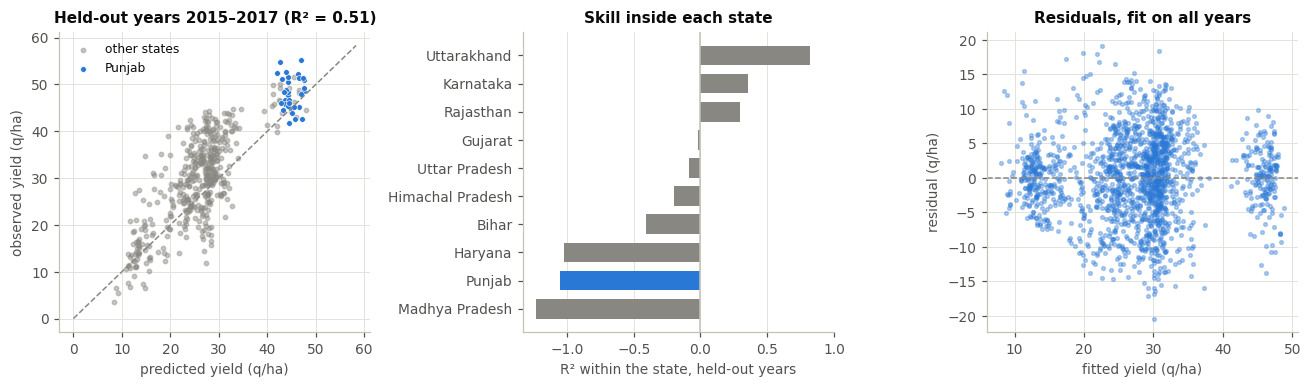

saved results\figures\yield_fit_diagnostics.png


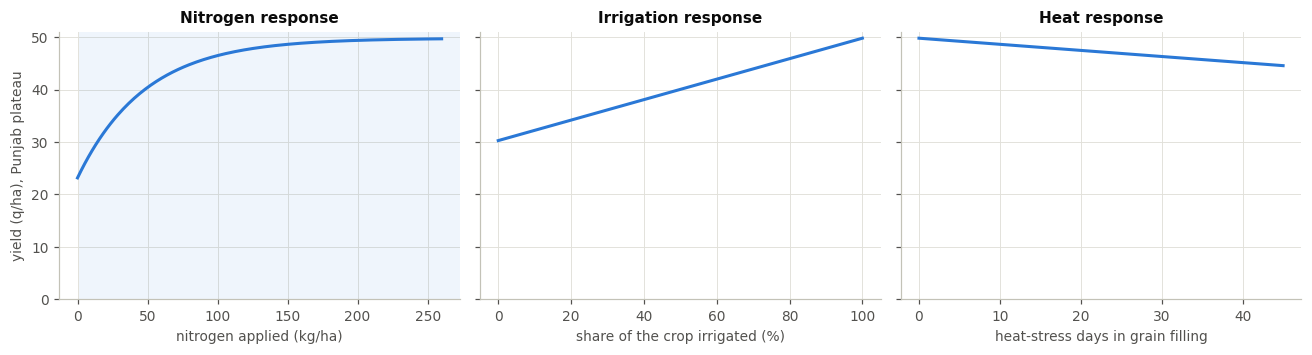

saved results\figures\yield_response_curves.png


In [10]:
held = rep["holdout_rows"]
fig, axes = plt.subplots(1, 3, figsize=(12, 3.6))
ax = axes[0]
is_region = held["state"].str.lower() == REGION.lower()
ax.scatter(held.loc[~is_region, "predicted"], held.loc[~is_region, "yield_q_ha"], s=8, color="#898781", alpha=0.45, label="other states")
ax.scatter(held.loc[is_region, "predicted"], held.loc[is_region, "yield_q_ha"], s=14, color=COLORS[0], edgecolor="white", lw=0.4, label=REGION.title())
lim = [0, max(held["predicted"].max(), held["yield_q_ha"].max()) + 3]
ax.plot(lim, lim, color=MUTED, lw=1, ls="--")
ax.set(xlabel="predicted yield (q/ha)", ylabel="observed yield (q/ha)", title=f"Held-out years {h['from_year']}–{held['year'].max()} (R² = {h['r2_test']:.2f})")
ax.legend(loc="upper left")

ax = axes[1]
by_state = pd.Series(h["by_state"]).sort_values()
ax.barh(by_state.index, by_state.values, color=[COLORS[0] if s.lower() == REGION.lower() else "#898781" for s in by_state.index], height=0.7)
ax.axvline(0, color="#c3c2b7", lw=1)
ax.set(xlabel="R² within the state, held-out years", title="Skill inside each state")
ax.set_xlim(max(-2.5, by_state.min() - 0.1), 1)
ax.grid(axis="y", visible=False)

ax = axes[2]
res = rep["data"].assign(residual=lambda d: d["yield_q_ha"] - d["predicted"])
ax.scatter(res["predicted"], res["residual"], s=6, color=COLORS[0], alpha=0.35)
ax.axhline(0, color=MUTED, lw=1, ls="--")
ax.set(xlabel="fitted yield (q/ha)", ylabel="residual (q/ha)", title="Residuals, fit on all years")
fig.tight_layout()
show(fig, "yield_fit_diagnostics")

fig, axes = plt.subplots(1, 3, figsize=(12, 3.3), sharey=True)
n_grid = np.linspace(0, 260, 200)
axes[0].plot(n_grid, model.y_max * model.n_term(n_grid), color=COLORS[0])
axes[0].axvspan(*rep["n_range_kg_ha"], color=COLORS[0], alpha=0.07, lw=0)
axes[0].set(xlabel="nitrogen applied (kg/ha)", ylabel=f"yield (q/ha), {REGION.title()} plateau", title="Nitrogen response", ylim=(0, None))
share = np.linspace(0, 1, 100)
axes[1].plot(share * 100, model.y_max * (1 - model.k_dry * (1 - share)), color=COLORS[0])
axes[1].set(xlabel="share of the crop irrigated (%)", title="Irrigation response")
days = np.linspace(0, 45, 100)
axes[2].plot(days, model.y_max * model.heat_term(days), color=COLORS[0])
axes[2].set(xlabel="heat-stress days in grain filling", title="Heat response")
fig.tight_layout()
show(fig, "yield_response_curves")

**Reading the fit honestly.**

* The pooled model explains about half of the yield variance in held-out years, but most
  of that is *between* states and districts: irrigated, well-fertilised districts yield
  more. State means alone already reach R² = 0.40.
* **Inside the north-western states it has no skill at predicting year-to-year changes**:
  for the region's own held-out rows R² is negative, for the pooled fit and for the earlier
  single-region fit alike. Year-to-year yield variation in an irrigated district is driven
  by things neither model sees well (timing of heat and rain, lodging, disease).
* The nitrogen response is now estimated from districts spanning almost the full range of
  doses, instead of being extrapolated below 89 kg/ha.
* The pooled panel does **not** support a yield loss from excess rain (it is reset to zero),
  nor a rain dependence of the rainfed loss. The loss the Haryana-only fit found for wet
  seasons was estimated from very few wet district-years.
* Heat-stress days carry a small but identified loss.
* The calibrated pesticide loss is about a third of the 0.35 placeholder used until now,
  and it is not statistically distinguishable from zero.
* The calibrated pesticide loss is about a third of the 0.35 placeholder used until now,
  and it is not statistically distinguishable from zero.
* The calibrated pesticide loss is about a third of the 0.35 placeholder used until now,
  and it is not statistically distinguishable from zero.

### Calibrating deficit response and potential yield

Two numbers tie the fit to the simulator, both set by `fit_yield_model`:

* `ky`, the response to unmet crop water demand, is chosen so that a season played with no
  irrigation loses on average what the panel says an unirrigated crop loses ($k_{dry}$),
  replacing the FAO literature value;
* `y_scale` lifts the potential yield so that the recommended schedule reproduces the
  region's observed mean yield (the fitted plateau is what farmers obtain *after* the
  losses that the simulator applies explicitly).

In [11]:
params_path = ROOT / cfg["env"]["fitted_params"]
model.save(params_path, source=f"ICRISAT district-level data ({fit_table['state'].nunique()} states, {fit_table['year'].min()}-"
                               f"{fit_table['year'].max()}) + NASA POWER district weather; region {REGION}")
print(f"ky = {model.ky:.3f}, y_scale = {model.y_scale:.3f}  ->  potential yield {model.y_max * model.y_scale:.1f} q/ha")
print("saved", params_path.relative_to(ROOT))
print(params_path.read_text().split("fit:")[0])

ky = 0.707, y_scale = 1.069  ->  potential yield 53.3 q/ha
saved configs\fitted_params.yaml
params:
  y_max: 49.82029383518054
  n_coef: 0.020839550299222492
  w_opt: 400.0
  w_excess: 0.0
  pest_loss: 0.11508672626908367
  soil_n: 30.0
  ky: 0.7065201360875861
  y_scale: 1.0690140464862448
  heat_coef: 0.00233718454254169
  k_dry: 0.39229838131505834
  r0: 1000000.0
source: ICRISAT district-level data (15 states, 2008-2017) + NASA POWER district weather;
  region punjab



## 4. Calibrating the environment

`FarmEnv` now reads the fitted parameters, replays real Ludhiana seasons and pays each
season's real price index. The `split` argument separates the years:

* `split="train"`: sowing years up to 2016, used for learning;
* `split="test"`: 2017 onwards, never seen during training.

The remaining dynamics (soil bucket size, crop coefficients, nitrogen timing efficiency,
pest growth, penalty weights) are stated assumptions listed in `env.DYNAMICS` and
`configs/default.yaml`; they are not fitted.

train seasons (32): 1985-2016
test seasons  (7): [2017, 2018, 2019, 2020, 2021, 2022, 2023]
yield model   : {'y_max': 49.8203, 'n_coef': 0.0208, 'w_opt': 400.0, 'w_excess': 0.0, 'pest_loss': 0.35, 'soil_n': 30.0, 'ky': 0.7065, 'y_scale': 1.1152, 'heat_coef': 0.0023, 'k_dry': 0.3923, 'r0': 1000000.0}
unit costs    : {'nitrogen_per_kg': 12.9, 'irrigation_per_mm': 2.86, 'pesticide_per_level': 1183.0, 'fixed_per_ha': 29450.0}


rain_mm         et0_mm        t_mean       late_t_max       price_index  \
         mean    std    mean    std   mean   std       mean   std        mean   
split                                                                           
test   149.52  58.64  555.00  34.41  18.11  0.88      31.57  2.26         1.0   
train  101.76  51.67  604.86  25.46  18.89  0.79      32.30  1.70         1.0   

             
        std  
split        
test   0.01  
train  0.04

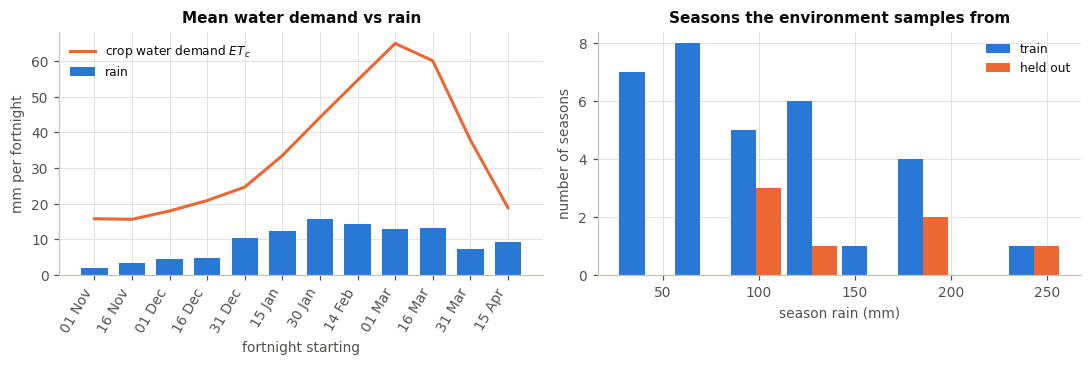

saved results\figures\env_calibration.png
mean season crop water demand: 409 mm, mean rain: 110 mm


In [12]:
env_train = FarmEnv(cfg["env"], split="train")
env_test = FarmEnv(cfg["env"], split="test")
print(f"train seasons ({len(env_train.seasons)}): {env_train.seasons[0]}-{env_train.seasons[-1]}")
print(f"test seasons  ({len(env_test.seasons)}): {env_test.seasons}")
print("yield model   :", {k: round(v, 4) for k, v in env_train.ym.params().items()})
print("unit costs    :", cfg["env"]["costs"])

split = np.where(summary["season"] <= cfg["env"]["train_end"], "train", "test")
display(summary.assign(split=split).merge(prices[["season", "price_index"]], on="season", how="left")
        .groupby("split")[["rain_mm", "et0_mm", "t_mean", "late_t_max", "price_index"]].agg(["mean", "std"]).round(2))

kc = np.array(env_train.dyn["kc"])
etc = seasons.assign(etc=seasons["et0_mm"] * kc[seasons["step"]])
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
ax = axes[0]
g = etc.groupby("step")
ax.plot(fx, g["etc"].mean(), color=COLORS[1], label="crop water demand $ET_c$")
ax.bar(fx, g["rain_mm"].mean(), color=COLORS[0], width=0.7, label="rain")
ax.set_xticks(fx); ax.set_xticklabels(labels, rotation=60, ha="right")
ax.set(xlabel="fortnight starting", ylabel="mm per fortnight", title="Mean water demand vs rain")
ax.legend(loc="upper left")
ax = axes[1]
tot = etc.groupby("season")[["etc", "rain_mm"]].sum()
ax.hist([tot.loc[train_years, "rain_mm"], tot.loc[test_years, "rain_mm"]], bins=8, color=[COLORS[0], COLORS[1]],
        label=["train", "held out"], rwidth=0.9)
ax.set(xlabel="season rain (mm)", ylabel="number of seasons", title="Seasons the environment samples from")
ax.legend()
fig.tight_layout()
show(fig, "env_calibration")
print(f"mean season crop water demand: {tot['etc'].mean():.0f} mm, mean rain: {tot['rain_mm'].mean():.0f} mm")

## 5. Sanity checks

Before training we check that the environment behaves: observations stay inside the
declared space, episodes last exactly $T$ steps, a random policy produces a wide but finite
reward distribution, and the extreme policies are ordered sensibly: applying nothing earns
almost nothing, applying everything at the maximum earns clearly less than the recommended
schedule (it buys a little yield at a large cost), and the recommended schedule reproduces
the observed mean yield.

observation: {'stage': 1.0, 'soil_moisture': 0.88, 'soil_n': 0.78, 'pest': 0.0, 'cum_rain': 0.27, 'cum_n': 1.3, 'cum_water': 1.16, 'price_index': 0.97, 'last_rain': 0.11, 'last_et0': 0.98, 'et_ratio': 1.0}


,profit,profit_std,reward,yield,n_total,irrigation_total,pesticide_total
policy,,,,,,,
no_input,4150.7,5571.5,4150.7,13.9,0.0,0.0,0.0
recommended,79308.0,6994.2,77708.0,46.3,120.0,300.0,1.0
always_max,59421.8,6203.0,52460.3,52.0,480.0,900.0,24.0


random policy over 800 episodes: reward mean 67,080, std 9,738, min 34,304, max 91,874 INR/ha


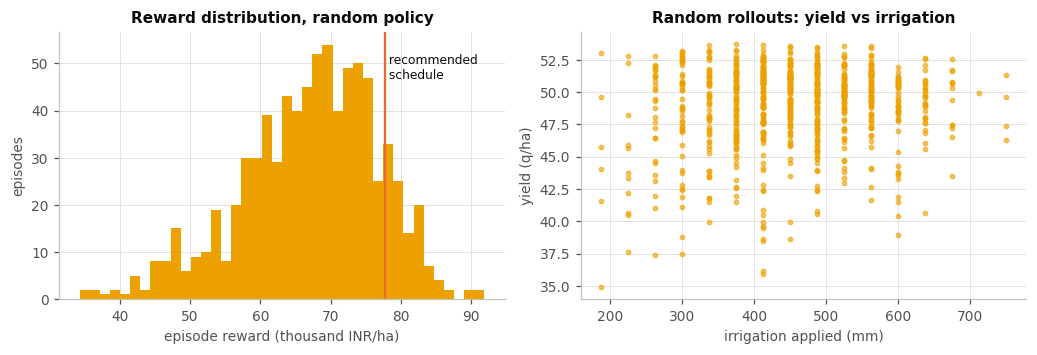

saved results\figures\sanity_random_policy.png


In [13]:
random_eps = evaluate(env_train, {"random": BASELINES["random"]}, seeds_per_season=25, seed0=SEED)
obs, _ = env_train.reset(seed=SEED)
assert env_train.observation_space.contains(obs), "observation outside the declared space"
steps, done = 0, False
while not done:
    obs, r, done, _, info = env_train.step(BASELINES["random"](obs, env_train))
    assert env_train.observation_space.contains(obs) and np.isfinite(r)
    steps += 1
assert steps == env_train.T
print("observation:", dict(zip(OBS_NAMES, np.round(obs, 2))))

always_max = lambda o, e: np.array([2, 2, 2])
checks = summarise(evaluate(env_train, {"no_input": BASELINES["no_input"], "recommended": BASELINES["recommended"],
                                        "always_max": always_max}, seeds_per_season=5, seed0=SEED))
display(checks.round(1))
print(f"random policy over {len(random_eps)} episodes: reward mean {random_eps['reward'].mean():,.0f}, "
      f"std {random_eps['reward'].std():,.0f}, min {random_eps['reward'].min():,.0f}, max {random_eps['reward'].max():,.0f} INR/ha")

fig, axes = plt.subplots(1, 2, figsize=(9.5, 3.3))
axes[0].hist(random_eps["reward"] / 1000, bins=40, color=COLORS[3])
axes[0].axvline(checks.loc["recommended", "reward"] / 1000, color=COLORS[1], lw=1.5)
axes[0].text(checks.loc["recommended", "reward"] / 1000, axes[0].get_ylim()[1] * 0.92, " recommended\n schedule", fontsize=8, va="top")
axes[0].set(xlabel="episode reward (thousand INR/ha)", ylabel="episodes", title="Reward distribution, random policy")
axes[1].scatter(random_eps["irrigation_total"], random_eps["yield"], s=8, color=COLORS[3], alpha=0.6)
axes[1].set(xlabel="irrigation applied (mm)", ylabel="yield (q/ha)", title="Random rollouts: yield vs irrigation")
fig.tight_layout()
show(fig, "sanity_random_policy")

## 6. Training PPO

The agent is our own implementation (`src/farmrl/agents/ppo.py`): a shared two-layer tanh
network with three categorical heads (one per input) and a value head, the clipped surrogate
objective, generalised advantage estimation, minibatch Adam updates and gradient clipping.
It is trained only on the training seasons; seeds are fixed, so the run is repeatable.

> **Note on the outputs below.** Sections 2.5 and 3 were re-executed after the FAO data arrived, so `configs/fitted_params.yaml` now holds the calibrated `pest_loss`. The training, evaluation and policy-analysis outputs in sections 6–10 were produced before that, with the placeholder `pest_loss = 0.35` (run `v2`). Re-running the notebook or `scripts/run_all.py --run-name v3` retrains with the calibrated value.

In [14]:
set_seed(SEED)
env_train = FarmEnv(cfg["env"], split="train")
env_train.reset(seed=SEED)
agent = PPO(env_train, cfg["train"])
print("hyperparameters:", cfg["train"])
history = agent.learn(cfg["train"]["total_timesteps"])
to_kinr = env_train.reward_scale / 1000
history = [h * to_kinr for h in history]
(ROOT / "results/models").mkdir(parents=True, exist_ok=True)
agent.save(ROOT / "results/models/ppo_latest.pt")
json.dump(history, open(ROOT / "results/train_history.json", "w"))
print(f"{len(history)} iterations of {cfg['train']['n_steps']} steps; "
      f"mean episode return: first {history[0]:.1f}, last {history[-1]:.1f} thousand INR/ha")

hyperparameters: {'total_timesteps': 200000, 'lr': 0.0003, 'gamma': 0.99, 'gae_lambda': 0.95, 'clip_eps': 0.2, 'n_steps': 2048, 'batch_size': 64, 'epochs': 10, 'hidden': 64, 'ent_coef': 0.01, 'vf_coef': 0.5}


97 iterations of 2048 steps; mean episode return: first 67.2, last 87.1 thousand INR/ha


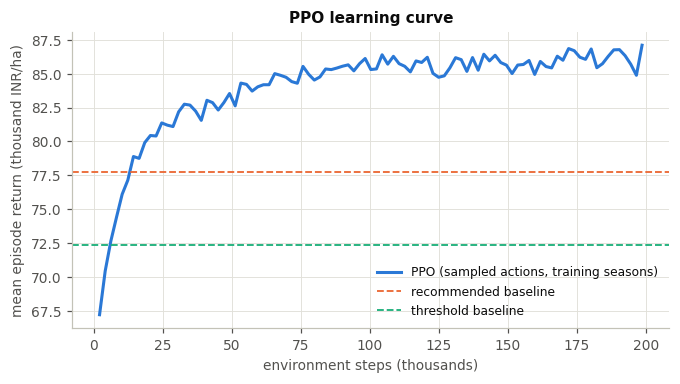

saved results\figures\training_curve.png


In [15]:
ref = summarise(evaluate(env_train, {k: BASELINES[k] for k in ("recommended", "threshold")}, seeds_per_season=5, seed0=SEED))
fig, ax = plt.subplots(figsize=(7, 3.5))
steps_axis = (np.arange(len(history)) + 1) * cfg["train"]["n_steps"] / 1000
ax.plot(steps_axis, history, color=COLORS[0], label="PPO (sampled actions, training seasons)")
for name in ref.index:
    ax.axhline(ref.loc[name, "reward"] / 1000, color=POLICY_COLORS[name], lw=1.2, ls="--", label=f"{name} baseline")
ax.set(xlabel="environment steps (thousands)", ylabel="mean episode return (thousand INR/ha)", title="PPO learning curve")
ax.legend(loc="lower right")
show(fig, "training_curve")

## 7. Evaluation on held-out seasons

All policies are run on the held-out seasons (2017 onwards). Pest growth is random, so
each season is replayed with 30 seeds, shared across policies. PPO acts greedily (argmax).
*Profit* is net of input and fixed costs but excludes the environmental penalty terms;
*reward* includes them.

In [16]:
policies = {"ppo": lambda o, e: agent.predict(o), **{k: BASELINES[k] for k in ("threshold", "recommended", "random", "no_input")}}
episodes = evaluate(env_test, policies, seeds_per_season=cfg["eval"]["seeds_per_season"])
table = summarise(episodes)
episodes.to_csv(ROOT / "results/eval_episodes.csv", index=False)
json.dump(table.round(3).to_dict(orient="index"), open(ROOT / "results/eval.json", "w"), indent=2)

pretty = table.rename(columns={"profit": "profit (INR/ha)", "profit_std": "profit std", "reward": "reward (INR/ha)",
                               "yield": "yield (q/ha)", "n_total": "N (kg/ha)", "irrigation_total": "irrigation (mm)",
                               "pesticide_total": "pesticide (dose units)"})
display(pretty.style.format("{:,.0f}").format({"yield (q/ha)": "{:.1f}", "pesticide (dose units)": "{:.1f}"}))
by_season = episodes.pivot_table(index="season", columns="policy", values="profit")[list(policies)]
print("mean profit by held-out season (INR/ha):")
display(by_season.round(0).assign(rain_mm=summary.set_index("season")["rain_mm"]))

,profit (INR/ha),profit std,reward (INR/ha),yield (q/ha),N (kg/ha),irrigation (mm),pesticide (dose units)
policy,,,,,,,
ppo,86630.456346,4429.655464,84639.083776,50.8,202.285714,251.428571,3.3
threshold,72157.057451,3789.620292,70267.533642,46.4,140.000000,235.714286,7.1
recommended,76403.634156,4991.744124,74803.634156,45.1,120.000000,300.000000,1.0
random,70907.981352,8198.879731,67487.918768,48.9,244.476190,436.785714,11.8
no_input,8981.772998,7457.207185,8981.772998,15.8,0.000000,0.000000,0.0


mean profit by held-out season (INR/ha):


policy,ppo,threshold,recommended,random,no_input,rain_mm
season,,,,,,
2017,86584.0,72461.0,77234.0,68836.0,2569.0,92.76
2018,92110.0,77229.0,83532.0,76505.0,14322.0,179.95
2019,93661.0,77391.0,80847.0,77913.0,24041.0,257.76
2020,82445.0,69099.0,72661.0,64365.0,1273.0,98.47
2021,83296.0,67658.0,68007.0,66257.0,10100.0,171.41
2022,82606.0,69515.0,75682.0,71087.0,4361.0,135.21
2023,85712.0,71745.0,76863.0,71394.0,6205.0,111.10


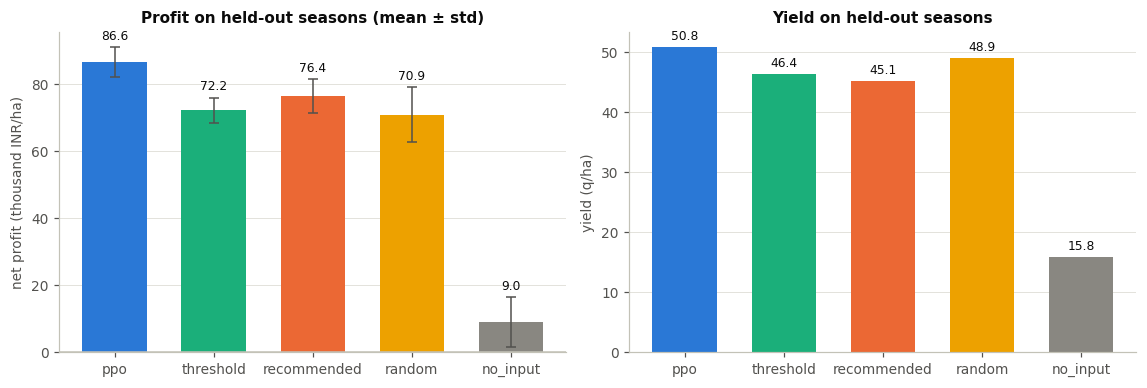

saved results\figures\eval_profit_yield.png


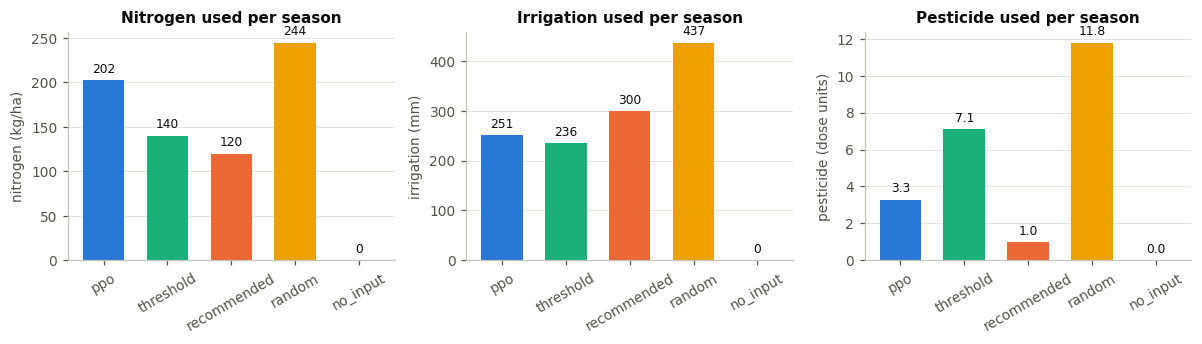

saved results\figures\eval_inputs_used.png


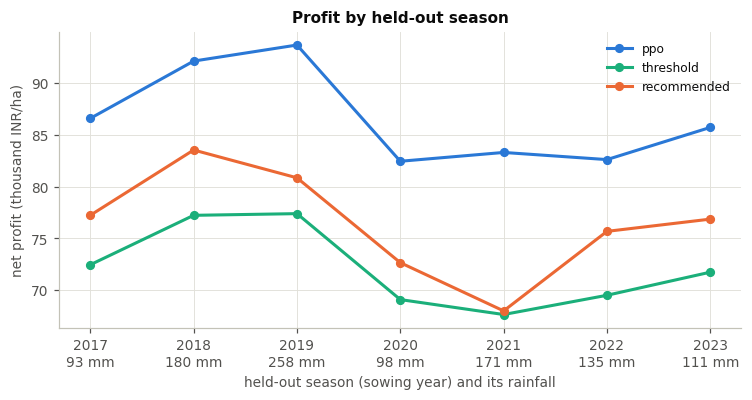

saved results\figures\eval_profit_by_season.png


In [17]:
names = list(policies)
colors = [POLICY_COLORS[n] for n in names]
fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.6))
ax = axes[0]
bars = ax.bar(names, table.loc[names, "profit"] / 1000, yerr=table.loc[names, "profit_std"] / 1000, color=colors,
              width=0.65, capsize=3, error_kw={"elinewidth": 1, "ecolor": "#52514e"})
ax.bar_label(bars, labels=[f"{v / 1000:.1f}" for v in table.loc[names, "profit"]], padding=3, fontsize=8)
ax.axhline(0, color="#c3c2b7", lw=1)
ax.set(ylabel="net profit (thousand INR/ha)", title="Profit on held-out seasons (mean ± std)")
ax.grid(axis="x", visible=False)
ax = axes[1]
bars = ax.bar(names, table.loc[names, "yield"], color=colors, width=0.65)
ax.bar_label(bars, fmt="%.1f", padding=3, fontsize=8)
ax.set(ylabel="yield (q/ha)", title="Yield on held-out seasons")
ax.grid(axis="x", visible=False)
fig.tight_layout()
show(fig, "eval_profit_yield")

fig, axes = plt.subplots(1, 3, figsize=(11, 3.2))
for ax, col, ylabel in zip(axes, ["n_total", "irrigation_total", "pesticide_total"],
                           ["nitrogen (kg/ha)", "irrigation (mm)", "pesticide (dose units)"]):
    bars = ax.bar(names, table.loc[names, col], color=colors, width=0.65)
    ax.bar_label(bars, fmt="%.0f" if col != "pesticide_total" else "%.1f", padding=3, fontsize=8)
    ax.set(ylabel=ylabel, title=ylabel.split(" (")[0].capitalize() + " used per season")
    ax.tick_params(axis="x", rotation=30); ax.grid(axis="x", visible=False)
fig.tight_layout()
show(fig, "eval_inputs_used")

fig, ax = plt.subplots(figsize=(8, 3.5))
for n in ["ppo", "threshold", "recommended"]:
    ax.plot(by_season.index, by_season[n] / 1000, marker="o", color=POLICY_COLORS[n], label=n)
ax.set_xticks(by_season.index)
ax.set_xticklabels([f"{s}\n{summary.set_index('season').loc[s, 'rain_mm']:.0f} mm" for s in by_season.index])
ax.set(xlabel="held-out season (sowing year) and its rainfall", ylabel="net profit (thousand INR/ha)", title="Profit by held-out season")
ax.legend()
show(fig, "eval_profit_by_season")

## 8. Policy analysis

What did the agent learn to do? First, its input schedule across a season, next to the
fixed recommended calendar, for the driest and the wettest held-out season. Then its
irrigation choice across *all* seasons as a function of how much rain fell.

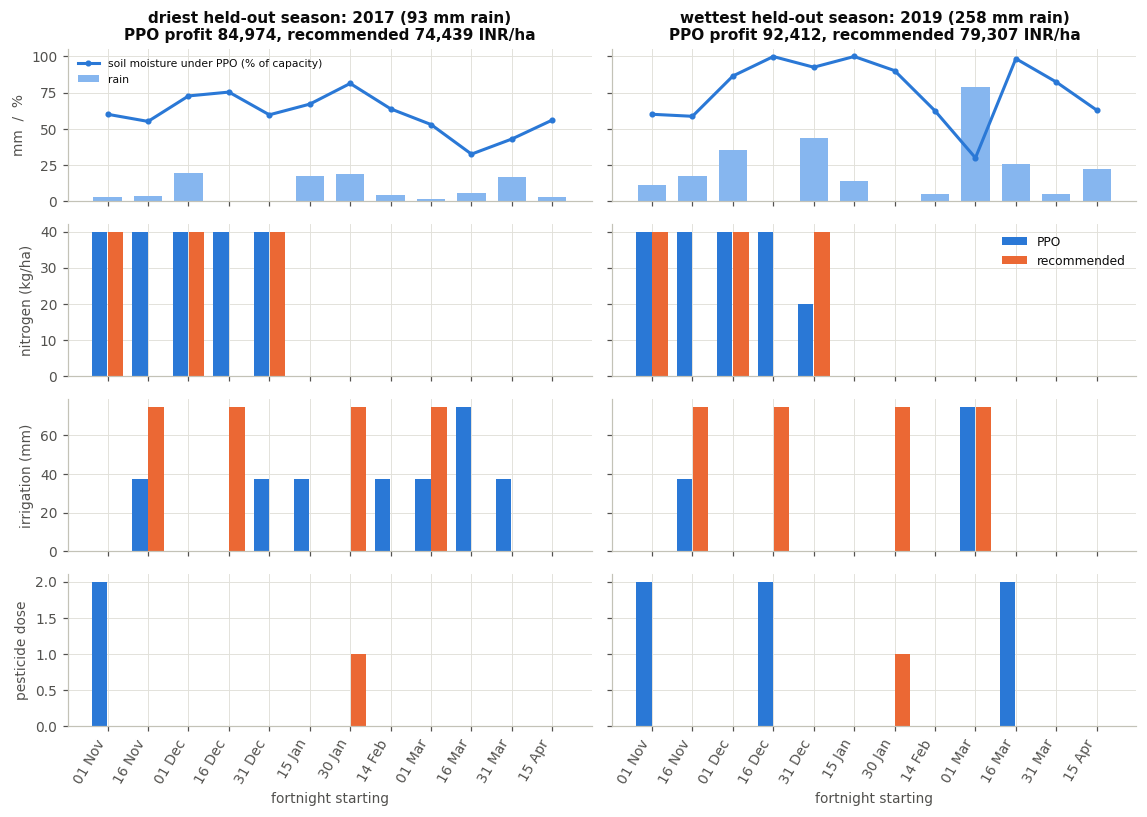

saved results\figures\policy_schedules_dry_vs_wet.png


In [18]:
test_rain = summary.set_index("season").loc[env_test.seasons, "rain_mm"]
dry, wet = int(test_rain.idxmin()), int(test_rain.idxmax())
ppo_policy = policies["ppo"]
fig, axes = plt.subplots(4, 2, figsize=(10.5, 7.5), sharex=True, sharey="row")
for j, (season, tag) in enumerate([(dry, "driest"), (wet, "wettest")]):
    tr_ppo = run_episode(env_test, ppo_policy, season=season, seed=SEED, trace=True)
    tr_rec = run_episode(env_test, BASELINES["recommended"], season=season, seed=SEED, trace=True)
    s_ppo, s_rec = tr_ppo["steps"], tr_rec["steps"]
    xs = s_ppo["step"].to_numpy()
    axes[0, j].bar(xs, s_ppo["rain"], color="#86b6ef", width=0.7, label="rain")
    axes[0, j].plot(xs, s_ppo["soil_moisture"] * 100, color=COLORS[0], marker="o", ms=3, label="soil moisture under PPO (% of capacity)")
    axes[0, j].set_title(f"{tag} held-out season: {season} ({test_rain[season]:.0f} mm rain)\n"
                         f"PPO profit {tr_ppo['profit']:,.0f}, recommended {tr_rec['profit']:,.0f} INR/ha")
    for i, (col, ylabel) in enumerate([("nitrogen", "nitrogen (kg/ha)"), ("irrigation", "irrigation (mm)"), ("pesticide", "pesticide dose")], start=1):
        axes[i, j].bar(xs - 0.2, s_ppo[col], width=0.38, color=POLICY_COLORS["ppo"], label="PPO")
        axes[i, j].bar(xs + 0.2, s_rec[col], width=0.38, color=POLICY_COLORS["recommended"], label="recommended")
        axes[i, 0].set_ylabel(ylabel)
    axes[3, j].set_xticks(xs); axes[3, j].set_xticklabels(labels, rotation=60, ha="right"); axes[3, j].set_xlabel("fortnight starting")
axes[0, 0].set_ylabel("mm  /  %")
axes[0, 0].legend(loc="upper left", fontsize=7); axes[1, 1].legend(loc="upper right")
fig.tight_layout()
show(fig, "policy_schedules_dry_vs_wet")

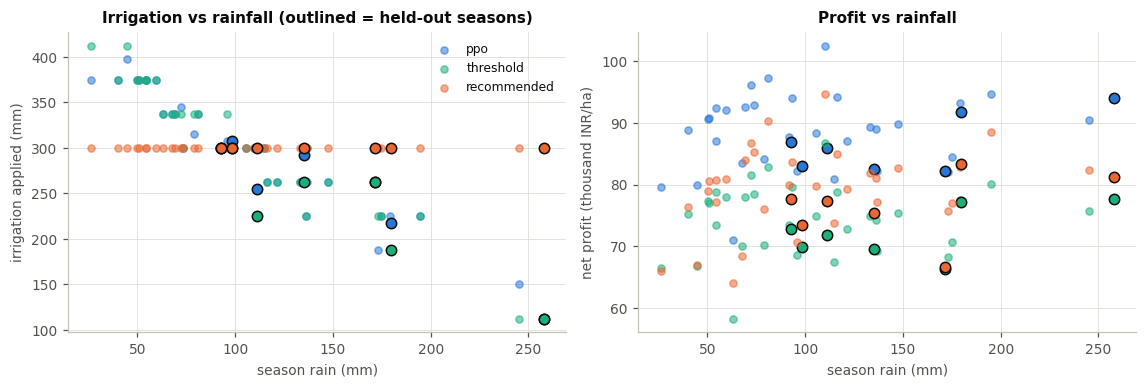

saved results\figures\policy_dry_vs_wet_years.png
PPO behaviour by rainfall tercile (all 39 seasons):


,rain_total,irrigation_total,n_total,pesticide_total,yield,profit
rain_total,,,,,,
dry third,55.9,360.0,200.9,2.0,50.7,87465.7
middle third,100.8,296.0,199.1,2.2,50.9,88770.8
wet third,174.3,223.8,196.6,2.9,51.6,88114.1


change in irrigation per extra mm of season rain: {'ppo': -1.14, 'recommended': 0.0, 'threshold': -1.24}


In [19]:
env_all = FarmEnv(cfg["env"], split="all")
behaviour = evaluate(env_all, {"ppo": ppo_policy, "threshold": BASELINES["threshold"], "recommended": BASELINES["recommended"]},
                     seeds_per_season=5, seed0=SEED)
per_season = behaviour.groupby(["policy", "season"], sort=False)[["irrigation_total", "n_total", "pesticide_total", "rain_total", "profit", "yield"]].mean().reset_index()

fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.6))
for name in ["ppo", "threshold", "recommended"]:
    d = per_season[per_season["policy"] == name]
    held = d["season"] > cfg["env"]["train_end"]
    axes[0].scatter(d["rain_total"][~held], d["irrigation_total"][~held], s=22, color=POLICY_COLORS[name], alpha=0.55, label=f"{name}")
    axes[0].scatter(d["rain_total"][held], d["irrigation_total"][held], s=46, color=POLICY_COLORS[name], edgecolor="#0b0b0b", lw=1)
    axes[1].scatter(d["rain_total"][~held], d["profit"][~held] / 1000, s=22, color=POLICY_COLORS[name], alpha=0.55, label=name)
    axes[1].scatter(d["rain_total"][held], d["profit"][held] / 1000, s=46, color=POLICY_COLORS[name], edgecolor="#0b0b0b", lw=1)
axes[0].set(xlabel="season rain (mm)", ylabel="irrigation applied (mm)", title="Irrigation vs rainfall (outlined = held-out seasons)")
axes[1].set(xlabel="season rain (mm)", ylabel="net profit (thousand INR/ha)", title="Profit vs rainfall")
axes[0].legend(); fig.tight_layout()
show(fig, "policy_dry_vs_wet_years")

ppo_seasons = per_season[per_season["policy"] == "ppo"].copy()
terciles = pd.qcut(ppo_seasons["rain_total"], 3, labels=["dry third", "middle third", "wet third"])
print("PPO behaviour by rainfall tercile (all 39 seasons):")
display(ppo_seasons.groupby(terciles, observed=True)[["rain_total", "irrigation_total", "n_total", "pesticide_total", "yield", "profit"]].mean().round(1))
slope = {n: np.polyfit(d["rain_total"], d["irrigation_total"], 1)[0] for n, d in per_season.groupby("policy")}
print("change in irrigation per extra mm of season rain:", {k: round(v, 2) for k, v in slope.items()})

## 9. Report figures from the saved run

The figures for the report are not drawn here: `scripts/run_all.py` saves a complete run to
`results/runs/<name>/` and `farmrl.viz.figures` draws each figure from it (300 dpi PNG and
PDF in the run's `figures/` folder). The cell below calls the same functions on the newest
run, so the notebook and the report cannot drift apart.

run 'v2', created 2026-10-10T17:45:46, 200,000 steps x 3 training seeds, 30 rollout seeds per season


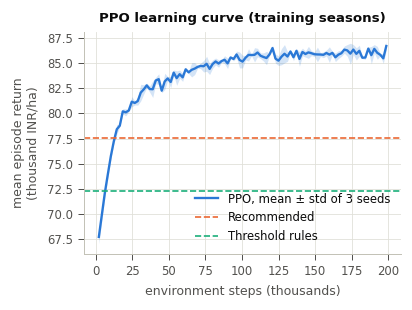

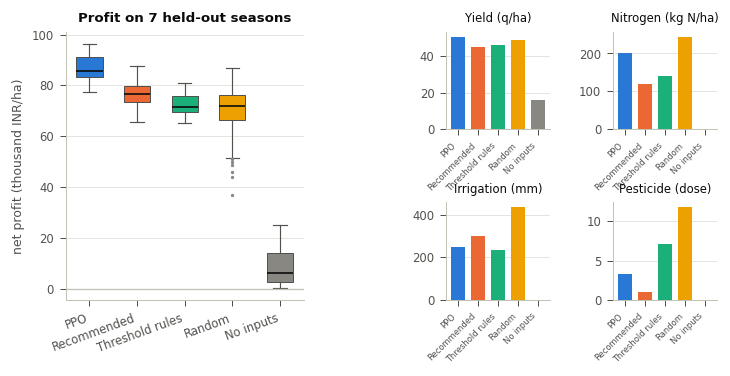

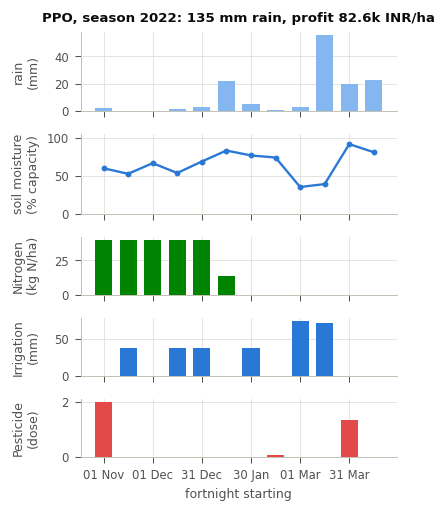

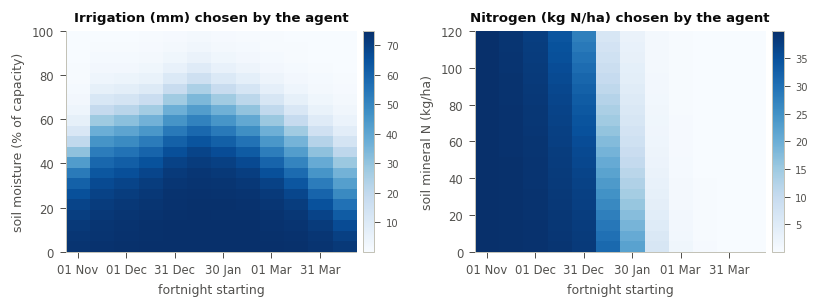

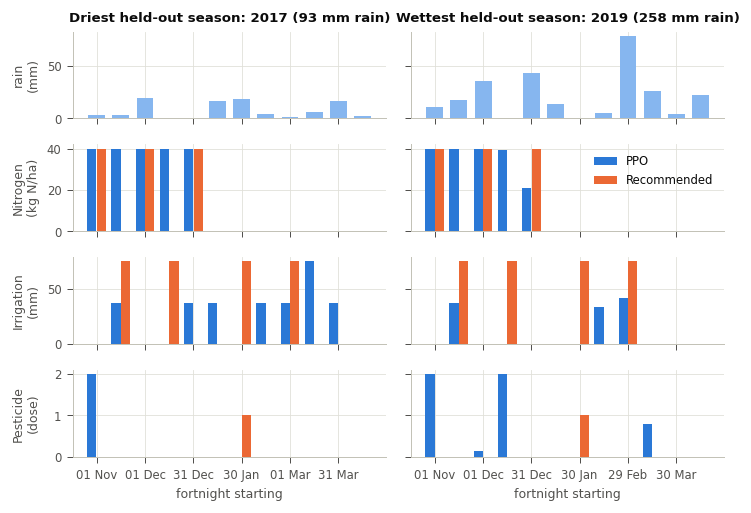

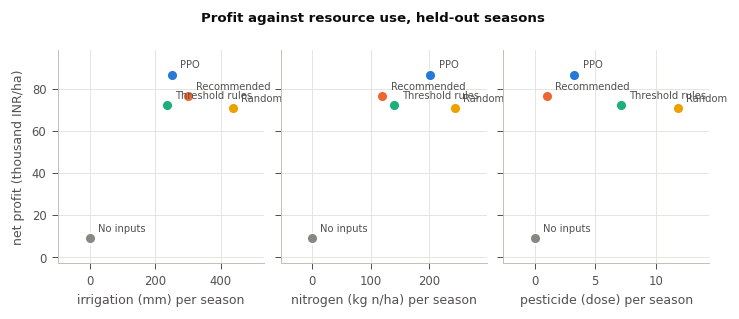

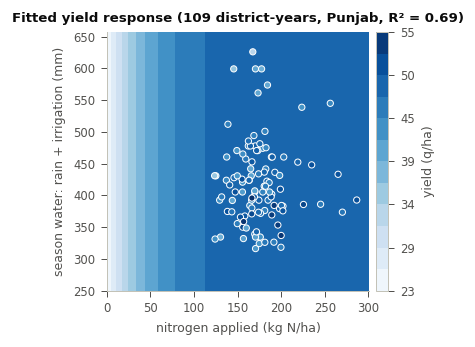

pesticide_response: skipped (no FAO pesticide table in data/processed (yield_df.csv not downloaded))


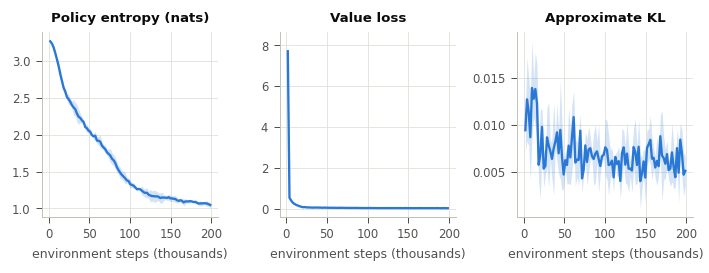

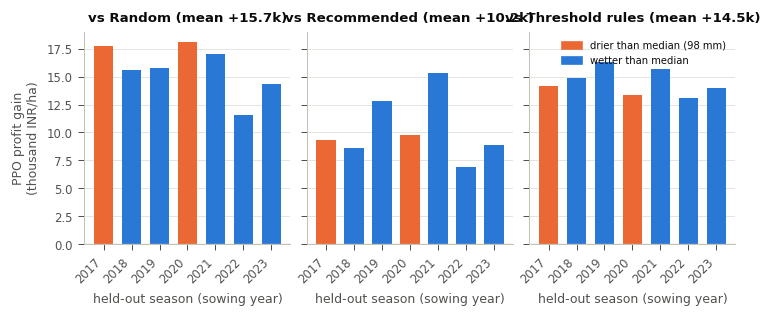

In [20]:
from farmrl import runs
from farmrl.viz import figures, style

try:
    latest = runs.get()
except FileNotFoundError as err:
    latest = None
    print(err)
if latest is not None:
    print(f"run '{latest.name}', created {latest.meta['created']}, {latest.meta['timesteps']:,} steps x "
          f"{len(latest.meta['train_seeds'])} training seeds, {latest.meta['rollout_seeds']} rollout seeds per season")
    style.apply()
    for name, draw in figures.FIGURES.items():
        try:
            fig = draw(latest)
        except figures.SkipFigure as why:
            print(f"{name}: skipped ({why})")
            continue
        display(fig)
        plt.close(fig)

## 10. Conclusions and limitations

**What the results show** (held-out seasons 2017–2023, 30 replicates each, Punjab configuration):

| Policy | Net profit (INR/ha) | Std | Yield (q/ha) | N (kg/ha) | Irrigation (mm) | Pesticide (doses) |
|---|---|---|---|---|---|---|
| PPO (ours) | 86,631 | 4,430 | 50.8 | 202 | 251 | 3.3 |
| Recommended calendar | 76,404 | 4,992 | 45.1 | 120 | 300 | 1.0 |
| Threshold rules | 72,157 | 3,790 | 46.4 | 140 | 236 | 7.1 |
| Random | 70,908 | 8,199 | 48.9 | 244 | 437 | 11.8 |
| No inputs | 8,982 | 7,457 | 15.8 | 0 | 0 | 0 |

* PPO earns about 10,200 INR/ha (13%) more than the recommended calendar and about 14,500
  INR/ha (20%) more than the threshold rules, and is ahead of both in all seven held-out
  seasons.
* It uses **16% less irrigation water** than the calendar (251 vs 300 mm) and still cuts
  irrigation by about 1.1 mm for every extra mm of rain, but applies much more nitrogen
  (202 vs 120 kg/ha) and more pesticide (3.3 vs 1 dose).
* Most of its advantage over the calendar now comes from nitrogen and pest control, not
  from water: with the pooled yield model, extra water no longer hurts the crop, so the
  calendar is not punished in wet years the way it was with the Haryana-only model.
* **A random policy reaches 82% of PPO's profit.** In this version of the simulator
  over-applying inputs costs money but hardly any yield, so the problem is more forgiving
  and the ranking of the rule-based baselines changed (the calendar now beats the threshold
  rules). The headline gain is therefore smaller and should be read with that in mind.

**What changed from the first version of the model** (Haryana-only fit, MSP prices):

| | First version | This version |
|---|---|---|
| Yield data | 70 district-years, Haryana | 1,719 district-years, 13 states (2,071 in 15 states before requiring irrigation data) |
| Fit | N + rain, single region | state fixed effects + N + irrigated share + rain + heat-stress days |
| Score | R² 0.24 in-sample | R² 0.69 in-sample, **0.51 on held-out years** (state means alone: 0.40) |
| Excess-water loss | fitted (yield falls above 332 mm) | not supported by the pooled data, set to zero |
| Water-deficit response | FAO constant 1.15 | 0.71, calibrated to the fitted loss of unirrigated wheat (39%) |
| Heat | none | 0.23% yield loss per day above 30 °C in grain filling |
| Punjab plateau | 46.8 q/ha (Haryana) | 49.8 q/ha (Punjab fixed effect) |
| Prices | MSP | Punjab farm harvest prices for 2008–2015, MSP elsewhere |
| PPO gain over the calendar | 14,900 INR/ha (21%) | 10,200 INR/ha (13%) |

**Limitations: read the numbers above as results in a simulator, not field advice.**

1. **The yield model explains differences between places, not between years.** On held-out
   years it scores R² = 0.51 overall, but inside Punjab and inside Haryana its R² is
   negative (as is the single-region fit's): it cannot predict which year will be good in
   an irrigated district. The agent's season-to-season decisions rest on the simulator's
   assumed dynamics, not on fitted year-to-year responses.
2. **Nitrogen is an all-crop annual district average**, not the wheat dose, and its effect
   is identified mostly across states, where it is confounded with irrigation and climate.
   The agent's 202 kg N/ha follows a curve that still rises slightly at high doses.
3. **Districts are the 1966 ones**, placed at the centroid of today's same-named district;
   weather for large old districts is approximate. West Bengal and most of Maharashtra
   drop out for lack of irrigation data.
4. **These results still use the placeholder `pest_loss = 0.35`.** The FAO series has since
   been used to calibrate it at about 0.12 (± 0.08, 24 national years, not distinguishable
   from zero); retraining with that value will lower the return to spraying. The rest of
   the pest sub-model (growth, kill rate) remains assumed, and the agent's heavy early
   spraying exploits it.
5. **Harvest prices cover seasons 2008–2015 only**; all held-out seasons are priced at the
   MSP. Price risk is close to absent.
6. **Several dynamics are assumed rather than calibrated**: soil water capacity, crop
   coefficients, nitrogen timing efficiency and leaching, and the penalty weights. Unit
   costs divide CACP per-hectare spending by an assumed number of applications; the
   nitrogen price is the notified urea price.
7. **The baselines were not tuned to the simulator**, whereas PPO was trained in it.
8. **Seven held-out seasons** is a small test set, and they are wetter than the training
   years.

**Next steps.** Add a year effect or within-district (difference) estimation so the model
captures year-to-year variation; retrain with the calibrated pesticide loss; get mandi prices; tune a
baseline on the training seasons; and test whether the excess-water loss reappears with
district rainfall from gauges rather than gridded data.